# 17 — Skenario 2 (S2): rs-fMRI + sMRI dengan GATv2 + Node-Attention Pooling

**Dataset:** ABIDE I + ABIDE II (turunan DCAN), 1.638 subjek, 34 situs
**Modalitas:** rs-fMRI + sMRI (morfometri korteks per parcel)
**Model:** model usulan yang **sama persis** dengan S1 (notebook 16): GATv2 + *node-attention pooling* + cabang linear FC multi-atlas + fusi atensi


| | |
| :--- | :--- |
| **Masukan** | `data/processed/kohort_dcan.csv` (1.638 subjek, fold `fold_gabungan`, notebook 09) · seperti S1 + morfometri 360 parcel × 5 (notebook 12/13) · probabilitas baseline LR `result/tabel/22_cache/C3_gab_tangent_<atlas>.npz` (dijelaskan di notebook 14) · prediksi skenario sebelumnya `result/tabel/25_S1_prediksi.csv (notebook 16)` |
| **Keluaran** | `result/tabel/26_S2_*.csv` (hasil per run, per fold, prediksi per subjek, uji McNemar) · `result/metrics/S2_ringkasan.json` · `result/figure/26_*.png` · cache pelatihan `result/tabel/26_cache_5run/` |

---

## Posisi S2 dalam rangkaian skenario

| Skenario | Notebook | Informasi yang dipakai |
| :---: | :---: | :--- |
| S1 | 16 | rs-fMRI: graf otak (fitur simpul = FC tangent) + cabang linear FC tangent 3 atlas |
| **S2** | **17 (ini)** | **S1 + sMRI**: 5 morfometri per parcel ditambahkan ke fitur simpul graf |
| S3 | 18 | S2 + fenotipik (usia, jenis kelamin, FIQ) sebagai cabang ketiga |
| S4 | 19 | **sama dengan S3**; hyperparameter dicari dengan *Optuna* di setiap fold |

**Pertanyaan S2:** apakah informasi **struktur otak** (sMRI) di setiap parcel menambah kemampuan model dibanding rs-fMRI saja (S1)?

### Apa yang berubah dari S1, dan apa yang tidak

| Bagian | S1 | S2 |
| :--- | :--- | :--- |
| Fitur simpul cabang graf | 379 nilai: baris FC tangent | **384 nilai: 379 baris FC tangent + 5 morfometri parcel itu** |
| Sisi graf | top-20 \|korelasi\| | sama |
| Cabang linear | FC tangent 3 atlas | sama (sMRI **tidak** dimasukkan ke sini) |
| Model, hyperparameter, fold, seed, 5 run | – | **sama persis** |

sMRI sengaja hanya dimasukkan ke **simpul graf**. Dengan begitu, selisih S2 − S1 bisa dibaca langsung sebagai sumbangan sMRI melalui graf. Inilah peran yang tidak bisa diambil cabang linear: setiap parcel membawa informasi **fungsi (FC) dan struktur (morfometri) sekaligus**, dan GATv2 bisa mempelajari interaksi keduanya antar parcel yang bertetangga.

Hasil S1 menunjukkan bahwa dengan FC saja, cabang graf tidak menambah informasi di atas cabang linear (per run 70,54% vs cabang linear 73,12%). Jadi S2 menguji apakah informasi baru di simpul membuat cabang graf berguna.

---

## Arsitektur model

```
                    ┌──────────────────────────────────────────────────────────┐
 graf otak HCP-360  │ CABANG GRAF                                              │
 simpul = parcel:   │ proyeksi + embedding ROI → 2 × GATv2 (4 head)            │──┐
  379 FC + 5 sMRI   │ → node-attention pooling sadar-ROI                       │  │
 sisi = FC top-20   └──────────────────────────────────────────────────────────┘  │   ┌────────────────┐
                                                                                  ├──►│ FUSI ATENSI    │──► MLP ──► [Kontrol, ASD]
                    ┌──────────────────────────────────────────────────────────┐  │   │ (bobot cabang) │
 FC tangent 3 atlas │ CABANG LINEAR                                            │──┘   └────────────────┘
 (±154 ribu nilai)  │ proyeksi PCA penuh → lapisan linear                      │
                    └──────────────────────────────────────────────────────────┘
               setiap cabang juga punya kepala klasifikasi bantu (deep supervision)
```

Penjelasan setiap komponen, alasan fusi atensi (termasuk percobaan penjumlahan logit yang ditolak), dan kesetaraan PCA penuh dengan Logistic Regression ada di notebook 16. Desain ini **dikunci untuk S1–S4**.

---

## Fitur sMRI: 5 morfometri per parcel

Diekstraksi di notebook 12 dari turunan DCAN (permukaan korteks fsLR32k), pada **360 parcel yang sama** dengan simpul graf:

| Fitur | Arti | Pengolahan |
| :--- | :--- | :--- |
| Luas permukaan | luas korteks parcel (mm²) | dibagi total luas korteks subjek → **proporsi** (koreksi ukuran kepala) |
| Volume GM | volume materi abu-abu parcel | dibagi total volume subjek → **proporsi** |
| Ketebalan | tebal korteks rata-rata (mm) | apa adanya |
| Kelengkungan | lengkung permukaan rata-rata | apa adanya |
| Kedalaman sulkus | seberapa dalam lipatan | apa adanya |

Lalu setiap (parcel, fitur) **distandardisasi dengan statistik data latih** fold tersebut, sama seperti fitur FC. Pengaruh usia dan jenis kelamin **tidak** diregresikan keluar di S2, karena:
1. informasi fenotipik baru masuk di S3, sehingga S2 tetap murni "rs-fMRI + sMRI";
2. di bangku uji sMRI (notebook 24, sekarang di arsip), koreksi usia/jenis kelamin tidak konsisten membantu (naik di gradient boosting, turun di LR).

### Ekspektasi yang jujur

Di bangku uji sMRI (notebook 24, sekarang di arsip), sMRI **sendirian** hanya mencapai ±57–60%, dan menggabungkannya dengan FC lewat rata-rata probabilitas tidak menaikkan akurasi. Sinyal sMRI untuk ASD memang lemah. Bedanya, di sini sMRI tidak berdiri sendiri: ia digabung dengan FC **di dalam setiap parcel**. Kalau hasilnya tetap setara S1, itu juga temuan sah: "informasi morfometri tidak menambah daya pembeda di atas konektivitas fungsional".

---

## Protokol

Sama persis dengan notebook 16: statistik fitur dari data latih setiap fold, *class weight* seimbang, *early stopping* pada potongan validasi 15% dari data latih, ambang 0,5, fold `fold_gabungan`, **5 run** (seed 0–4, sama dengan S1). Seed yang sama berarti potongan validasi dan urutan acak di S1 dan S2 identik, sehingga perbandingan S1 vs S2 per run adalah perbandingan **berpasangan**.

## Lama proses

Penyiapan fitur ±1,5 menit per fold, RAM ±4–5 GB. **Tutup kernel notebook lain sebelum menjalankan.** Pelatihan **±2–2,5 jam** (5 fold × 5 run). Hasil setiap fold disimpan ke `result/tabel/26_cache_5run/`; kalau terhenti, jalankan ulang dan fold yang sudah selesai akan dilewati.

## 1. Persiapan

In [1]:
import gc
import sys
import json
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import stats
from sklearn.metrics import confusion_matrix, roc_curve
from IPython.display import display
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT))
import importlib
import src.usulan
importlib.reload(src.usulan)          # selalu pakai versi terbaru src/usulan.py walau kernel belum di-restart
from src.metrics import hitung_metrik
from src.usulan import (DEVICE, ModelUsulan, buat_graf, fitur_linear_pca, fitur_simpul_baris, jalankan_cv_usulan, sisi_topk)

# ----- Parameter skenario (ditetapkan sebelum pelatihan) -----
SKENARIO = "S2"
ATLAS = {"gordon2014": 352, "hcp2016": 379, "markov2012": 205}   # jumlah ROI setiap atlas DCAN
ATLAS_GRAF = "hcp2016"
N_SIMPUL = 360                     # parcel korteks HCP (berada di urutan awal time series DCAN)
K_SISI = 20                        # setiap simpul dihubungkan ke 20 tetangga dengan |korelasi| terbesar
HIPER_MODEL = dict(hidden=64, n_layer=2, heads=4, dropout=0.5, dropout_input=0.2, dropedge=0.2, dropout_linear=0.2, bobot_bantu=0.5)
CFG_LATIH = dict(lr=1e-3, weight_decay=1e-3, batch_size=32, max_epochs=200, min_epochs=20, patience=40, val_size=0.15, seeds=(0, 1, 2, 3, 4))          # 5 seed = 5 run

PROC = ROOT / "data" / "processed"
FITUR_22 = PROC / "fitur_dcan_22"
CACHE_22 = ROOT / "result" / "tabel" / "22_cache"
TABEL_DIR = ROOT / "result" / "tabel"
FIG_DIR = ROOT / "result" / "figure"
METRIK_DIR = ROOT / "result" / "metrics"
CACHE_DIR = TABEL_DIR / "26_cache_5run"
for d in (TABEL_DIR, FIG_DIR, METRIK_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

kohort = pd.read_csv(PROC / "kohort_dcan.csv")
y = kohort["label"].to_numpy()
fold = kohort["fold_gabungan"].to_numpy()
situs = kohort["situs"].to_numpy()
dataset = kohort["dataset"].to_numpy()
F_SMRI = np.load(PROC / "fitur_smri_dcan" / "fitur_smri_dcan.npz", allow_pickle=True)
NAMA_PARCEL = F_SMRI["parcel_hcp2016"].astype(str)
print(f"Perangkat: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

ringkas_data = (kohort.assign(ASD=y, Kontrol=1 - y)
                .groupby("dataset").agg(Subjek=("label", "size"), ASD=("ASD", "sum"), Kontrol=("Kontrol", "sum"), Situs=("situs", "nunique"),
                                        **{"Usia rata-rata": ("usia", "mean")}))
ringkas_data.loc["Total"] = [len(kohort), y.sum(), (1 - y).sum(), kohort["situs"].nunique(), kohort["usia"].mean()]
ringkas_data.index = ringkas_data.index.map({"abide1": "ABIDE I", "abide2": "ABIDE II", "Total": "Total"})
display(ringkas_data.round(1).style.set_caption("Kohort ABIDE I + II (DCAN)"))

Perangkat: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


,Subjek,ASD,Kontrol,Situs,Usia rata-rata
dataset,,,,,
ABIDE I,886.000000,405.000000,481.000000,20.000000,16.900000
ABIDE II,752.000000,309.000000,443.000000,14.000000,15.300000
Total,1638.000000,714.000000,924.000000,34.000000,16.100000


## 2. Pembagian Fold

Fold sama dengan baseline LR dan skenario sebelumnya (notebook 09–14, 16), sehingga hasil S2 bisa dibandingkan langsung (uji McNemar per subjek) dengan S1 dan baseline Logistic Regression. Proporsi ASD dan proporsi ABIDE I/II di setiap fold seharusnya mirip.

In [2]:
tab_fold = pd.DataFrame({"Subjek uji": pd.Series(fold).value_counts().sort_index(),
                         "ASD (%)": pd.Series(y).groupby(fold).mean() * 100,
                         "ABIDE I": pd.Series(dataset == "abide1").groupby(fold).sum(),
                         "ABIDE II": pd.Series(dataset == "abide2").groupby(fold).sum(),
                         "Situs": pd.Series(situs).groupby(fold).nunique()})
tab_fold.index.name = "Fold"
display(tab_fold.round(1).style.set_caption("Isi setiap fold (data uji); data latih = empat fold lainnya"))

,Subjek uji,ASD (%),ABIDE I,ABIDE II,Situs
Fold,,,,,
0,328,44.500000,177,151,34
1,323,44.600000,172,151,34
2,335,44.200000,185,150,33
3,327,42.200000,177,150,33
4,325,42.500000,175,150,33


## 3. Membangun Graf Otak

Setiap subjek menjadi **satu graf**:
- **simpul**: 360 parcel korteks atlas HCP;
- **sisi**: setiap parcel dihubungkan ke 20 parcel lain dengan |korelasi| (Fisher z) terbesar, lalu dibuat simetris. Cara top-k per simpul menjamin **tidak ada simpul yang terisolasi**, berbeda dengan ambang global (mis. 20% pasangan terkuat) yang bisa membuat sebagian simpul tidak punya tetangga;
- **bobot sisi**: nilai korelasinya.

Sisi berasal dari korelasi per subjek, tidak dipelajari dari data latih, sehingga cukup dibuat sekali untuk semua fold.

In [3]:
t0 = time.perf_counter()
KORELASI = np.load(FITUR_22 / f"korelasi_{ATLAS_GRAF}.npy", mmap_mode="r")
SISI = sisi_topk(KORELASI, ATLAS[ATLAS_GRAF], N_SIMPUL, K_SISI)
n_sisi = np.array([s[0].shape[1] // 2 for s in SISI])
derajat0 = np.bincount(SISI[0][0][0].numpy(), minlength=N_SIMPUL)
print(f"Sisi graf siap untuk {len(SISI)} subjek ({time.perf_counter() - t0:.0f} detik)")
display(pd.DataFrame({"Simpul per graf": [N_SIMPUL], "Sisi tak berarah per graf (rata-rata)": [n_sisi.mean().round(0)],
                      "Kepadatan graf (%)": [(n_sisi.mean() / (N_SIMPUL * (N_SIMPUL - 1) / 2) * 100).round(2)],
                      "Derajat minimum (subjek pertama)": [derajat0.min()], "Simpul terisolasi": [int((derajat0 == 0).sum())]}))

Sisi graf siap untuk 1638 subjek (8 detik)


,Simpul per graf,Sisi tak berarah per graf (rata-rata),Kepadatan graf (%),Derajat minimum (subjek pertama),Simpul terisolasi
0,360,5129.0,7.94,20,0


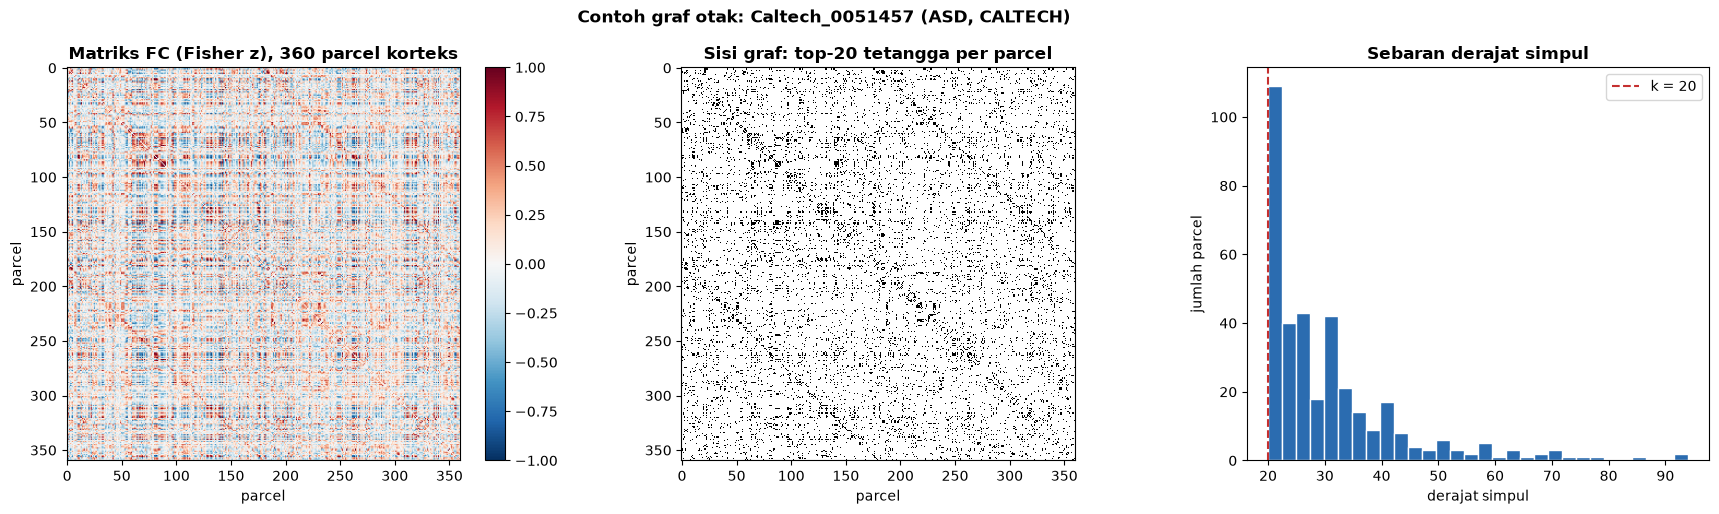

In [4]:
from src.usulan import _matriks
contoh = 0
M = _matriks(np.asarray(KORELASI[contoh:contoh + 1]), ATLAS[ATLAS_GRAF])[0, :N_SIMPUL, :N_SIMPUL]
A = np.zeros((N_SIMPUL, N_SIMPUL))
ei = SISI[contoh][0].numpy()
A[ei[0], ei[1]] = SISI[contoh][1].numpy().ravel()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1, 1, 0.9]})
im = axes[0].imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_title("Matriks FC (Fisher z), 360 parcel korteks", fontweight="bold")
plt.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].imshow(A != 0, cmap="Greys", interpolation="nearest")
axes[1].set_title(f"Sisi graf: top-{K_SISI} tetangga per parcel", fontweight="bold")
axes[2].hist(np.bincount(ei[0], minlength=N_SIMPUL), bins=30, color="#2B6CB0", edgecolor="white")
axes[2].axvline(K_SISI, color="#C53030", ls="--", label=f"k = {K_SISI}")
axes[2].set_xlabel("derajat simpul"); axes[2].set_ylabel("jumlah parcel"); axes[2].legend()
axes[2].set_title("Sebaran derajat simpul", fontweight="bold")
for ax in axes[:2]:
    ax.set_xlabel("parcel"); ax.set_ylabel("parcel")
fig.suptitle(f"Contoh graf otak: {kohort.loc[contoh, 'FILE_ID']} ({'ASD' if y[contoh] else 'Kontrol'}, {kohort.loc[contoh, 'situs']})", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "26_1_contoh_graf_otak.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Fitur sMRI per Parcel

Morfometri dimuat dari `fitur_smri_dcan.npz` (notebook 12). Urutan subjek dicek sama dengan `kohort_dcan.csv`, dan urutan parcel sama dengan simpul graf (360 parcel korteks HCP pertama).

Tabel dan grafik di bawah **hanya deskriptif**, untuk memahami data. Tidak ada pemilihan fitur atau parcel berdasarkan grafik ini, karena semua 5 fitur dan 360 parcel dipakai.

,Fitur,Rata-rata per parcel (mentah),Median |d| antar parcel,"Parcel dengan |d| ≥ 0,2",|d| terbesar
0,luas (proporsi),524.966003,0.035000,0,0.168000
1,volume GM (proporsi),1459.614014,0.039000,0,0.149000
2,ketebalan (mm),2.848000,0.033000,0,0.166000
3,kelengkungan,0.024000,0.038000,0,0.177000
4,kedalaman sulkus,-0.085000,0.042000,1,0.201000


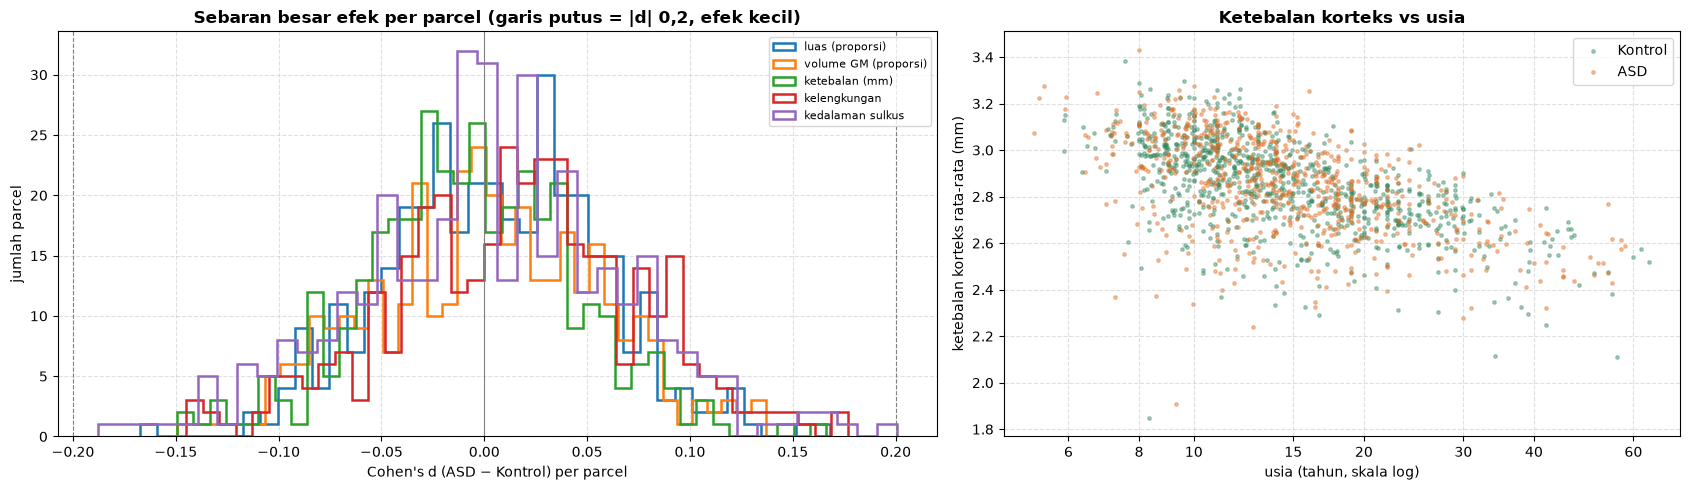

In [5]:
def morfo_relatif(M):
    """(N, R, 5): luas & volume -> proporsi terhadap total subjek; ketebalan, kelengkungan, sulkus apa adanya."""
    M = M.astype(np.float64).copy()
    M[:, :, 0] /= M[:, :, 0].sum(1, keepdims=True)
    M[:, :, 1] /= M[:, :, 1].sum(1, keepdims=True)
    return M.astype(np.float32)

assert list(F_SMRI["sub"]) == list(kohort["sub"]), "urutan subjek sMRI tidak sama dengan kohort"
MORFO_MENTAH = F_SMRI["morfo_hcp2016"]                       # (N, 360, 5)
MORFO = morfo_relatif(MORFO_MENTAH)
NAMA_MORFO = ["luas (proporsi)", "volume GM (proporsi)", "ketebalan (mm)", "kelengkungan", "kedalaman sulkus"]
assert MORFO.shape == (len(kohort), N_SIMPUL, 5) and np.isfinite(MORFO).all()

def cohen_d(a, b):
    return (a.mean(0) - b.mean(0)) / np.sqrt((a.var(0, ddof=1) + b.var(0, ddof=1)) / 2)

d_parcel = cohen_d(MORFO[y == 1], MORFO[y == 0])            # (360, 5): efek ASD − Kontrol per parcel
display(pd.DataFrame({
    "Fitur": NAMA_MORFO,
    "Rata-rata per parcel (mentah)": MORFO_MENTAH.mean((0, 1)),
    "Median |d| antar parcel": np.median(np.abs(d_parcel), axis=0),
    "Parcel dengan |d| ≥ 0,2": (np.abs(d_parcel) >= 0.2).sum(0),
    "|d| terbesar": np.abs(d_parcel).max(0),
}).round(3).style.set_caption("Morfometri per parcel: besar perbedaan ASD vs Kontrol (Cohen's d, deskriptif)"))

fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.3, 1]})
for j, n in enumerate(NAMA_MORFO):
    axes[0].hist(d_parcel[:, j], bins=40, histtype="step", lw=1.8, label=n)
axes[0].axvline(0, color="gray", lw=0.8)
for v in (-0.2, 0.2):
    axes[0].axvline(v, color="gray", ls="--", lw=0.8)
axes[0].set_xlabel("Cohen's d (ASD − Kontrol) per parcel"); axes[0].set_ylabel("jumlah parcel"); axes[0].legend(fontsize=8)
axes[0].set_title("Sebaran besar efek per parcel (garis putus = |d| 0,2, efek kecil)", fontweight="bold")
tebal = MORFO_MENTAH[:, :, 2].mean(1)
for lab, w, nama in [(0, "#2F855A", "Kontrol"), (1, "#DD6B20", "ASD")]:
    axes[1].scatter(kohort["usia"][y == lab], tebal[y == lab], s=6, alpha=0.4, color=w, label=nama)
axes[1].set_xscale("log"); axes[1].set_xticks([6, 8, 10, 15, 20, 30, 40, 60]); axes[1].set_xticklabels(["6", "8", "10", "15", "20", "30", "40", "60"])
axes[1].minorticks_off(); axes[1].set_xlabel("usia (tahun, skala log)"); axes[1].set_ylabel("ketebalan korteks rata-rata (mm)")
axes[1].legend(); axes[1].set_title("Ketebalan korteks vs usia", fontweight="bold")
for ax in axes:
    ax.grid(alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "26_2_morfometri_per_parcel.png", dpi=150, bbox_inches="tight")
plt.show()

def standar_latih(X, idx_latih):
    """Standardisasi per (parcel, fitur) dengan statistik data latih."""
    mu = X[idx_latih].mean(0, keepdims=True)
    sd = X[idx_latih].std(0, keepdims=True) + 1e-6
    return ((X - mu) / sd).astype(np.float32)

## 5. Fitur Simpul dan Fitur Cabang Linear (per Fold)

Fitur FC bergantung pada fold karena dihitung dari **FC tangent**, yang acuannya adalah rata-rata geometrik kovarians **subjek latih** fold tersebut (berkas `tangent_<atlas>_gab_<k>.npy` dari notebook 10; langkahnya dijelaskan di notebook 11). Morfometri tidak bergantung fold, tetapi standardisasinya memakai statistik data latih fold tersebut.

| Fitur | Bentuk per subjek | Pengolahan (statistik dari data latih fold) |
| :--- | :--- | :--- |
| Fitur simpul cabang graf | 360 × **384** = 379 baris tangent HCP + 5 morfometri | standardisasi per (parcel, fitur), FC dan morfometri masing-masing |
| Fitur cabang linear | ±3.900 skor PCA (3 atlas) | standardisasi per fitur → proyeksi ke seluruh komponen utama data latih |

Fungsi `siapkan_fold` dipanggil sekali per fold. Hasil fold terakhir disimpan di memori, sehingga pemeriksaan di bawah (fold 0) langsung dipakai ulang saat pelatihan.

In [6]:
_simpan = {}

def siapkan_fold(k, idx_latih_penuh):
    """Data PyG untuk SEMUA subjek pada fold k; statistik fitur hanya dari idx_latih_penuh."""
    if _simpan.get("fold") == k:
        return _simpan["data"]
    _simpan.clear()
    gc.collect()                       # lepaskan fitur fold sebelumnya (±1 GB) sebelum membuat yang baru
    V = {a: np.load(FITUR_22 / f"tangent_{a}_gab_{k}.npy", mmap_mode="r") for a in ATLAS}
    X_fc = fitur_simpul_baris(V[ATLAS_GRAF], ATLAS[ATLAS_GRAF], N_SIMPUL, idx_latih_penuh)              # (N, 360, 379)
    X_simpul = np.concatenate([X_fc, standar_latih(MORFO, idx_latih_penuh)], axis=2)                    # (N, 360, 384)
    del X_fc
    X_linear = fitur_linear_pca([V[a] for a in ATLAS], idx_latih_penuh)
    data = buat_graf(y, X_simpul, SISI, X_linear=X_linear)
    _simpan.update(fold=k, data=data, X_simpul=X_simpul, X_linear=X_linear)
    return data

t0 = time.perf_counter()
latih0 = np.where(fold != 0)[0]
data0 = siapkan_fold(0, latih0)
Xs, Xl = _simpan["X_simpul"], _simpan["X_linear"]
display(pd.DataFrame({
    "Fitur": ["simpul (cabang graf)", "linear (cabang linear)"],
    "Bentuk": [f"{Xs.shape[0]} × {Xs.shape[1]} × {Xs.shape[2]}", f"{Xl.shape[0]} × {Xl.shape[1]}"],
    "Rata-rata data latih": [float(Xs[latih0].mean()), float(Xl[latih0].mean())],
    "SD data latih": [float(Xs[latih0].std()), float(Xl[latih0].std())],
    "Nilai tidak finit": [int((~np.isfinite(Xs)).sum()), int((~np.isfinite(Xl)).sum())],
}).round(4).style.set_caption(f"Fitur fold 0 ({time.perf_counter() - t0:.0f} detik)"))
display(pd.DataFrame({"Bagian fitur simpul": ["FC tangent (kolom 0–378)", "morfometri (kolom 379–383)"],
                      "Rata-rata data latih": [float(Xs[latih0][:, :, :379].mean()), float(Xs[latih0][:, :, 379:].mean())],
                      "SD data latih": [float(Xs[latih0][:, :, :379].std()), float(Xs[latih0][:, :, 379:].std())]}).round(4))
print("Contoh satu objek graf:", data0[0])

,Fitur,Bentuk,Rata-rata data latih,SD data latih,Nilai tidak finit
0,simpul (cabang graf),1638 × 360 × 384,0.000000,0.998700,0
1,linear (cabang linear),1638 × 3927,-0.000000,0.027600,0


,Bagian fitur simpul,Rata-rata data latih,SD data latih
0,FC tangent (kolom 0–378),0.0,0.9987
1,morfometri (kolom 379–383),0.0,0.9985


Contoh satu objek graf: Data(x=[360, 384], edge_index=[2, 11108], edge_attr=[11108, 1], y=[1], x_lin=[1, 3927])


## 6. Model dan Pemeriksaan Bentuk Tensor

Sebelum pelatihan, satu batch kecil dilewatkan ke model untuk memastikan bentuk tensor setiap tahap sudah benar.

In [7]:
def buat_model(contoh):
    return ModelUsulan(N_SIMPUL, d_simpul=contoh.x.size(1), d_linear=contoh.x_lin.size(1), **HIPER_MODEL)

from torch_geometric.loader import DataLoader
model_cek = buat_model(data0[0]).to(DEVICE).eval()
b = next(iter(DataLoader(data0[:4], batch_size=4))).to(DEVICE)
with torch.no_grad():
    logit = model_cek(b)
display(pd.DataFrame([
    {"Tahap": "input fitur simpul (4 graf digabung)", "Bentuk": tuple(b.x.shape)},
    {"Tahap": "input sisi (edge_index)", "Bentuk": tuple(b.edge_index.shape)},
    {"Tahap": "input cabang linear", "Bentuk": tuple(b.x_lin.shape)},
    {"Tahap": "bobot atensi parcel α (per subjek)", "Bentuk": tuple(model_cek.alpha().shape)},
    {"Tahap": "bobot cabang β (graf, linear)", "Bentuk": tuple(model_cek.beta_terakhir.shape)},
    {"Tahap": "keluaran logits [Kontrol, ASD]", "Bentuk": tuple(logit.shape)},
]))
param = {n: sum(p.numel() for p in model_cek.cabang[n].parameters()) for n in model_cek.nama_cabang}
param["fusi + kepala"] = sum(p.numel() for p in model_cek.parameters()) - sum(param.values())
display(pd.DataFrame({"Bagian": list(param), "Jumlah parameter": list(param.values())}).style.set_caption(
    f"Total parameter: {sum(param.values()):,}"))
assert torch.allclose(model_cek.alpha().sum(1), torch.ones(4, device=DEVICE)), "α setiap subjek harus berjumlah 1"
del model_cek, b, data0, Xs, Xl      # nama-nama ini menahan fitur fold 0 (±1 GB) di memori; lepaskan sebelum pelatihan
gc.collect()

,Tahap,Bentuk
0,input fitur simpul (4 graf digabung),"(1440, 384)"
1,input sisi (edge_index),"(2, 42624)"
2,input cabang linear,"(4, 3927)"
3,bobot atensi parcel α (per subjek),"(4, 360)"
4,"bobot cabang β (graf, linear)","(4, 2)"
5,"keluaran logits [Kontrol, ASD]","(4, 2)"


,Bagian,Jumlah parameter
0,graf,167813
1,linear,251392
2,fusi + kepala,6919


76

## 7. Pelatihan 5-Fold

| Hyperparameter | Nilai |
| :--- | :--- |
| Dimensi tersembunyi, lapis GATv2, head | 64, 2, 4 |
| Dropout (umum / input simpul / sisi / input linear) | 0,5 / 0,2 / 0,2 / 0,2 |
| Optimizer | AdamW, lr 10⁻³, weight decay 10⁻³, cosine annealing |
| Batch, epoch maksimum, *patience* | 32, 200, 40 (minimal 20 epoch) |
| Loss | cross-entropy berbobot kelas + 0,5 × rata-rata loss kepala bantu |
| Pengulangan | 5 run (seed 0–4) |

Sel berikut adalah bagian terlama. Setiap baris log menunjukkan satu seed selesai, dan setiap fold yang selesai langsung disimpan.

In [8]:
t0 = time.perf_counter()
HASIL = jalankan_cv_usulan(y, situs, fold, siapkan_fold, buat_model, cfg=CFG_LATIH, cache_dir=CACHE_DIR)
_simpan.clear()
print(f"\nSelesai dalam {(time.perf_counter() - t0) / 60:.1f} menit (≈0 berarti semua fold dibaca dari cache).")

    fold 0 seed 0: epoch terbaik  40 | AUC val 77.19 | 3.6 menit
    fold 0 seed 1: epoch terbaik  72 | AUC val 72.13 | 5.2 menit
    fold 0 seed 2: epoch terbaik  28 | AUC val 75.54 | 3.3 menit
    fold 0 seed 3: epoch terbaik  46 | AUC val 70.82 | 4.2 menit
    fold 0 seed 4: epoch terbaik  36 | AUC val 74.66 | 3.7 menit
  fold 0: ACC 72.26 | AUC 80.32 (20 menit berjalan)
    fold 1 seed 0: epoch terbaik  25 | AUC val 73.25 | 3.1 menit
    fold 1 seed 1: epoch terbaik  67 | AUC val 73.20 | 5.2 menit
    fold 1 seed 2: epoch terbaik  20 | AUC val 75.92 | 2.9 menit
    fold 1 seed 3: epoch terbaik  55 | AUC val 73.08 | 4.6 menit
    fold 1 seed 4: epoch terbaik 107 | AUC val 74.68 | 7.2 menit
  fold 1: ACC 70.28 | AUC 74.93 (44 menit berjalan)
    fold 2 seed 0: epoch terbaik  38 | AUC val 76.96 | 3.8 menit
    fold 2 seed 1: epoch terbaik 163 | AUC val 73.11 | 9.8 menit
    fold 2 seed 2: epoch terbaik 105 | AUC val 77.28 | 7.1 menit
    fold 2 seed 3: epoch terbaik  36 | AUC val 76.9

## 8. Hasil

### 8.1 Hasil 5 run

Setiap baris adalah satu validasi silang 5-fold lengkap dengan seed berbeda. Metrik setiap run = rata-rata 5 fold. Baris terakhir adalah **hasil utama S2**: rata-rata ± SD antar run.

In [9]:
P_LR = np.mean([np.load(CACHE_22 / f"C3_gab_tangent_{a}.npz")["p"] for a in ATLAS], axis=0)
N_RUN = HASIL["p_run"].shape[1]
KOLOM = {"accuracy": "Akurasi", "balanced": "Balanced acc.", "sensitivity": "Sensitivitas", "specificity": "Spesifisitas",
         "precision": "Presisi", "f1": "F1", "auc": "AUC"}

def metrik_per_fold(p):
    df = pd.DataFrame([{"fold": k, **hitung_metrik(y[fold == k], p[fold == k])} for k in sorted(np.unique(fold))])
    df["balanced"] = (df["sensitivity"] + df["specificity"]) / 2
    return df

def rata_fold(p):
    return metrik_per_fold(p)[list(KOLOM)].mean() * 100

tab_run = pd.DataFrame([rata_fold(HASIL["p_run"][:, r]) for r in range(N_RUN)], index=[f"run {r + 1} (seed {r})" for r in range(N_RUN)])
tab_run.columns = [f"{KOLOM[k]} (%)" for k in tab_run.columns]
tab_run_tampil = tab_run.round(2).astype(str)
tab_run_tampil.loc["Rata-rata ± SD antar run"] = [f"{m:.2f} ± {s:.2f}" for m, s in zip(tab_run.mean(), tab_run.std(ddof=1))]
display(tab_run_tampil.style.set_caption(f"S2: {N_RUN} run × 5-fold (1.638 subjek)"))
tab_run_tampil.to_csv(TABEL_DIR / "26_S2_per_run.csv")

,Akurasi (%),Balanced acc. (%),Sensitivitas (%),Spesifisitas (%),Presisi (%),F1 (%),AUC (%)
run 1 (seed 0),70.32,69.8,65.1,74.5,66.93,65.61,78.03
run 2 (seed 1),69.76,67.59,50.44,84.75,72.32,58.93,78.34
run 3 (seed 2),71.25,70.21,61.94,78.48,69.38,65.14,77.27
run 4 (seed 3),72.14,70.58,58.74,82.43,72.59,64.74,77.83
run 5 (seed 4),71.3,70.22,62.22,78.21,69.27,65.21,77.41
Rata-rata ± SD antar run,70.95 ± 0.93,69.68 ± 1.20,59.69 ± 5.64,79.68 ± 3.99,70.10 ± 2.37,63.93 ± 2.81,77.78 ± 0.44


### 8.2 Perbandingan dengan baseline

| Baris | Arti | SD |
| :--- | :--- | :--- |
| **S2 model usulan (5 run)** | hasil utama | antar run |
| S2 ensemble 5 run | probabilitas kelima run dirata-rata | antar fold |
| kepala bantu: cabang graf / cabang linear | prediksi kepala bantu satu cabang pada model yang sama (ensemble 5 run). **Bukan** model terpisah. Notebook ablasi tidak dibuat; sumbangan setiap komponen dibaca dari perbandingan berpasangan S1 → S3 | antar fold |
| Baseline LR (notebook 10) | FC tangent 3 atlas, subjek dan fold sama. Penjelasan lengkap di notebook 14; label di tabel dan grafik tetap "notebook 22" (nomor lama notebook 10) karena probabilitasnya dibuat di sana | antar fold |

In [10]:
PRED = {"S2 ensemble 5 run": HASIL["p"], "  kepala bantu: cabang graf": HASIL["p_graf"],
        "  kepala bantu: cabang linear": HASIL["p_linear"], "Baseline LR (notebook 22)": P_LR}

def ringkas_fold(p):
    df = metrik_per_fold(p)
    return {f"{v} (%)": f"{df[k].mean() * 100:.2f} ± {df[k].std(ddof=0) * 100:.2f}" for k, v in KOLOM.items()}

tab_hasil = pd.DataFrame({"S2 model usulan (5 run)": tab_run_tampil.loc["Rata-rata ± SD antar run"].to_dict(),
                          **{n: ringkas_fold(p) for n, p in PRED.items()}}).T
display(tab_hasil.style.set_caption("S2 vs baseline"))

per_fold = metrik_per_fold(HASIL["p"]).set_index("fold")[list(KOLOM)] * 100
per_fold["LR akurasi"] = metrik_per_fold(P_LR).set_index("fold")["accuracy"] * 100
display(per_fold.round(2).style.set_caption("S2 ensemble per fold (%)"))

tab_hasil.to_csv(TABEL_DIR / "26_S2_ringkasan.csv")
per_fold.to_csv(TABEL_DIR / "26_S2_per_fold.csv")
pd.DataFrame({"FILE_ID": kohort["FILE_ID"], "dataset": dataset, "situs": situs, "fold": fold, "y_true": y,
              "p_ensemble": HASIL["p"], **{f"p_run{r + 1}": HASIL["p_run"][:, r] for r in range(N_RUN)},
              "p_graf": HASIL["p_graf"], "p_linear": HASIL["p_linear"], "p_lr": P_LR}).to_csv(TABEL_DIR / "26_S2_prediksi.csv", index=False)
with open(METRIK_DIR / "S2_ringkasan.json", "w", encoding="utf-8") as f:
    json.dump({"skenario": SKENARIO, "notebook": "26", "n_subjek": int(len(y)), "n_run": int(N_RUN),
               "rata_rata_antar_run": tab_run.mean().round(4).to_dict(), "sd_antar_run": tab_run.std(ddof=1).round(4).to_dict(),
               "per_run": tab_run.round(4).to_dict(orient="index"), "ensemble": rata_fold(HASIL["p"]).round(4).to_dict(),
               "hiper_model": HIPER_MODEL, "cfg_latih": {k: list(v) if isinstance(v, tuple) else v for k, v in CFG_LATIH.items()},
               "k_sisi": K_SISI, "fusi": "penjumlahan logit (Wide & Deep)"}, f, indent=2)

,Akurasi (%),Balanced acc. (%),Sensitivitas (%),Spesifisitas (%),Presisi (%),F1 (%),AUC (%)
S2 model usulan (5 run),70.95 ± 0.93,69.68 ± 1.20,59.69 ± 5.64,79.68 ± 3.99,70.10 ± 2.37,63.93 ± 2.81,77.78 ± 0.44
S2 ensemble 5 run,73.07 ± 1.72,71.64 ± 1.46,60.51 ± 2.89,82.77 ± 3.36,73.32 ± 3.22,66.20 ± 1.57,79.29 ± 2.28
kepala bantu: cabang graf,67.76 ± 3.36,67.48 ± 2.81,65.53 ± 2.68,69.43 ± 7.53,62.92 ± 4.77,64.01 ± 1.67,73.09 ± 2.90
kepala bantu: cabang linear,73.48 ± 2.29,71.92 ± 2.08,59.68 ± 3.17,84.16 ± 4.07,74.77 ± 4.59,66.25 ± 2.25,80.91 ± 1.83
Baseline LR (notebook 22),73.23 ± 3.48,71.83 ± 3.48,61.14 ± 5.65,82.52 ± 3.84,73.18 ± 4.59,66.50 ± 4.52,81.35 ± 2.14


,accuracy,balanced,sensitivity,specificity,precision,f1,auc,LR akurasi
fold,,,,,,,,
0,72.260000,70.660000,56.160000,85.160000,75.230000,64.310000,80.320000,72.260000
1,70.280000,69.310000,60.420000,78.210000,69.050000,64.440000,74.930000,67.180000
2,74.030000,72.930000,63.510000,82.350000,74.020000,68.360000,81.350000,77.310000
3,73.390000,72.100000,63.770000,80.420000,70.400000,66.920000,79.270000,73.700000
4,75.380000,73.200000,58.700000,87.700000,77.880000,66.940000,80.610000,75.690000


### 8.3 Uji kebermaknaan terhadap baseline

Uji McNemar membandingkan prediksi benar/salah **per subjek** antara dua model pada subjek uji yang sama. Setiap run diuji terhadap LR, ditambah ensemble dan kepala bantu setiap cabang. Karena ada beberapa perbandingan, nilai p dikoreksi dengan metode Holm.

In [11]:
def mcnemar(pa, pb):
    A, B = (pa >= 0.5).astype(int) == y, (pb >= 0.5).astype(int) == y
    n01, n10 = int((~A & B).sum()), int((A & ~B).sum())
    return {"Selisih akurasi (poin)": round((B.mean() - A.mean()) * 100, 2), "Hanya benar di model": n01, "Hanya benar di LR": n10,
            "p": stats.binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0}

UJI = {**{f"S2 run {r + 1}": HASIL["p_run"][:, r] for r in range(N_RUN)}, **{n: p for n, p in PRED.items() if not n.startswith("Baseline")}}
uji = pd.DataFrame([{"Model (dibanding baseline LR)": n.strip(), **mcnemar(P_LR, p)} for n, p in UJI.items()])
urut = np.argsort(uji["p"].to_numpy())
holm = np.minimum(1, np.maximum.accumulate(uji["p"].to_numpy()[urut] * (len(uji) - np.arange(len(uji)))))
uji.loc[uji.index[urut], "p Holm"] = holm
uji["Kesimpulan"] = np.where(uji["p Holm"] >= 0.05, "setara (tidak berbeda bermakna)",
                             np.where(uji["Selisih akurasi (poin)"] > 0, "lebih baik secara bermakna", "lebih rendah secara bermakna"))
display(uji.round(4).style.set_caption("Uji McNemar + koreksi Holm"))
uji.to_csv(TABEL_DIR / "26_S2_uji_mcnemar.csv", index=False)

,Model (dibanding baseline LR),Selisih akurasi (poin),Hanya benar di model,Hanya benar di LR,p,p Holm,Kesimpulan
0,S2 run 1,-2.930000,114,162,0.004600,0.027500,lebih rendah secara bermakna
1,S2 run 2,-3.480000,100,157,0.000500,0.003200,lebih rendah secara bermakna
2,S2 run 3,-2.010000,105,138,0.039900,0.199400,setara (tidak berbeda bermakna)
3,S2 run 4,-1.100000,108,126,0.266400,0.799200,setara (tidak berbeda bermakna)
4,S2 run 5,-1.950000,118,150,0.058100,0.232300,setara (tidak berbeda bermakna)
5,S2 ensemble 5 run,-0.180000,88,91,0.881200,1.000000,setara (tidak berbeda bermakna)
6,kepala bantu: cabang graf,-5.490000,166,256,0.000000,0.000100,lebih rendah secara bermakna
7,kepala bantu: cabang linear,0.240000,52,48,0.764400,1.000000,setara (tidak berbeda bermakna)


### 8.4 Perbandingan dengan S1: apakah sMRI menambah informasi?

Ini pertanyaan utama S2. S1 dan S2 memakai fold dan seed yang sama, jadi **run ke-r di S2 dibandingkan dengan run ke-r di S1** (berpasangan):
- selisih akurasi per run, beserta rata-ratanya;
- uji t berpasangan antar 5 run (apakah selisihnya konsisten, bukan kebetulan seed);
- uji McNemar per subjek antara ensemble S2 dan ensemble S1.

In [12]:
S1 = pd.read_csv(TABEL_DIR / "25_S1_prediksi.csv")
assert (S1["FILE_ID"].to_numpy() == kohort["FILE_ID"].to_numpy()).all(), "urutan subjek S1 dan S2 berbeda"
P1_RUN = S1[[f"p_run{r + 1}" for r in range(N_RUN)]].to_numpy()
banding = pd.DataFrame({"run": [f"run {r + 1}" for r in range(N_RUN)],
                        "Akurasi S1 (%)": [rata_fold(P1_RUN[:, r])["accuracy"] for r in range(N_RUN)],
                        "Akurasi S2 (%)": [rata_fold(HASIL["p_run"][:, r])["accuracy"] for r in range(N_RUN)],
                        "AUC S1 (%)": [rata_fold(P1_RUN[:, r])["auc"] for r in range(N_RUN)],
                        "AUC S2 (%)": [rata_fold(HASIL["p_run"][:, r])["auc"] for r in range(N_RUN)]})
banding["Selisih akurasi (S2 − S1)"] = banding["Akurasi S2 (%)"] - banding["Akurasi S1 (%)"]
banding["Selisih AUC (S2 − S1)"] = banding["AUC S2 (%)"] - banding["AUC S1 (%)"]
t_acc = stats.ttest_rel(banding["Akurasi S2 (%)"], banding["Akurasi S1 (%)"])
t_auc = stats.ttest_rel(banding["AUC S2 (%)"], banding["AUC S1 (%)"])
display(banding.round(2).style.set_caption(
    f"S2 vs S1 per run | rata-rata selisih akurasi {banding['Selisih akurasi (S2 − S1)'].mean():+.2f} poin (uji t berpasangan p = {t_acc.pvalue:.3f}), "
    f"AUC {banding['Selisih AUC (S2 − S1)'].mean():+.2f} poin (p = {t_auc.pvalue:.3f})"))

uji_s1 = pd.DataFrame([{"Perbandingan": "ensemble S1 → ensemble S2", **mcnemar(S1["p_ensemble"].to_numpy(), HASIL["p"])},
                       {"Perbandingan": "kepala bantu graf S1 → S2", **mcnemar(S1["p_graf"].to_numpy(), HASIL["p_graf"])}])
uji_s1 = uji_s1.rename(columns={"Hanya benar di model": "Hanya benar di S2", "Hanya benar di LR": "Hanya benar di S1"})
uji_s1["Bermakna (p < 0,05)"] = np.where(uji_s1["p"] < 0.05, "ya", "tidak")
display(uji_s1.round(4).style.set_caption("Uji McNemar S1 vs S2 (subjek sama)"))
banding.to_csv(TABEL_DIR / "26_S2_vs_S1_per_run.csv", index=False)
uji_s1.to_csv(TABEL_DIR / "26_S2_vs_S1_mcnemar.csv", index=False)

,run,Akurasi S1 (%),Akurasi S2 (%),AUC S1 (%),AUC S2 (%),Selisih akurasi (S2 − S1),Selisih AUC (S2 − S1)
0,run 1,70.220000,70.320000,78.900000,78.030000,0.100000,-0.870000
1,run 2,70.490000,69.760000,77.640000,78.340000,-0.730000,0.700000
2,run 3,70.390000,71.250000,77.650000,77.270000,0.870000,-0.380000
3,run 4,70.870000,72.140000,78.080000,77.830000,1.270000,-0.250000
4,run 5,70.740000,71.300000,77.730000,77.410000,0.560000,-0.310000


,Perbandingan,Selisih akurasi (poin),Hanya benar di S2,Hanya benar di S1,p,"Bermakna (p < 0,05)"
0,ensemble S1 → ensemble S2,0.610000,88,78,0.485000,tidak
1,kepala bantu graf S1 → S2,-0.610000,162,172,0.622500,tidak


### 8.5 Grafik ringkasan

- **Kiri**: akurasi, balanced accuracy, dan AUC. Batang S2 = rata-rata 5 run (titik = setiap run); batang lain = ensemble/baseline (titik = setiap fold);
- **Tengah**: kurva ROC seluruh subjek uji;
- **Kanan**: confusion matrix S2 ensemble (ambang 0,5).

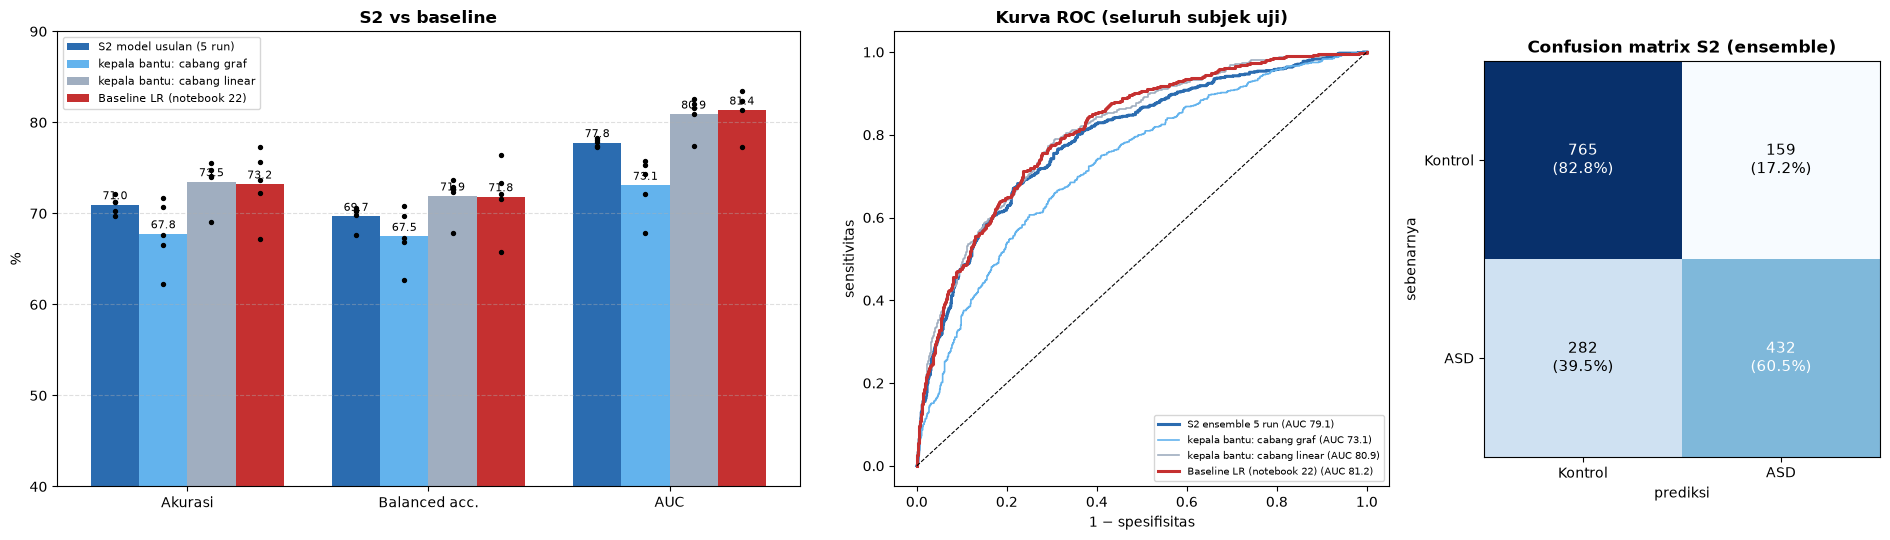

In [13]:
WARNA = {"S2 model usulan (5 run)": "#2B6CB0", "  kepala bantu: cabang graf": "#63B3ED", "  kepala bantu: cabang linear": "#A0AEC0",
         "Baseline LR (notebook 22)": "#C53030"}
metrik_plot = [("accuracy", "Akurasi"), ("balanced", "Balanced acc."), ("auc", "AUC")]
titik = {"S2 model usulan (5 run)": [[rata_fold(HASIL["p_run"][:, r])[m] for r in range(N_RUN)] for m, _ in metrik_plot]}
for n in ("  kepala bantu: cabang graf", "  kepala bantu: cabang linear", "Baseline LR (notebook 22)"):
    df = metrik_per_fold(PRED[n])
    titik[n] = [list(df[m] * 100) for m, _ in metrik_plot]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1.5, 1, 0.8]})
lebar = 0.8 / len(titik)
for j, (n, nilai) in enumerate(titik.items()):
    x = np.arange(len(metrik_plot)) + (j - (len(titik) - 1) / 2) * lebar
    rata = [np.mean(v) for v in nilai]
    axes[0].bar(x, rata, lebar, color=WARNA[n], label=n.strip())
    for xi, v in zip(x, nilai):
        axes[0].scatter(np.full(len(v), xi), v, color="black", s=8, zorder=3)
    for xi, r in zip(x, rata):
        axes[0].text(xi, max(r, 40) + 0.6, f"{r:.1f}", ha="center", fontsize=8)
axes[0].set_xticks(range(len(metrik_plot))); axes[0].set_xticklabels([t for _, t in metrik_plot])
axes[0].set_ylim(40, 90); axes[0].set_ylabel("%"); axes[0].legend(fontsize=8, loc="upper left")
axes[0].set_title("S2 vs baseline", fontweight="bold"); axes[0].grid(axis="y", alpha=0.4, ls="--")

WARNA_ROC = {"S2 ensemble 5 run": "#2B6CB0", **{k: v for k, v in WARNA.items() if k != "S2 model usulan (5 run)"}}
for n, p in PRED.items():
    fpr, tpr, _ = roc_curve(y, p)
    axes[1].plot(fpr, tpr, color=WARNA_ROC[n], lw=2.2 if n.startswith("S2") or n.startswith("Baseline") else 1.2,
                 label=f"{n.strip()} (AUC {hitung_metrik(y, p)['auc'] * 100:.1f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set_xlabel("1 − spesifisitas"); axes[1].set_ylabel("sensitivitas"); axes[1].legend(fontsize=7.5, loc="lower right")
axes[1].set_title("Kurva ROC (seluruh subjek uji)", fontweight="bold")

cm = confusion_matrix(y, (HASIL["p"] >= 0.5).astype(int))
axes[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum() * 100:.1f}%)", ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(["Kontrol", "ASD"]); axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["Kontrol", "ASD"])
axes[2].set_xlabel("prediksi"); axes[2].set_ylabel("sebenarnya"); axes[2].set_title("Confusion matrix S2 (ensemble)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "26_3_hasil_s2.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.6 Akurasi per dataset dan per situs

Model dilatih pada gabungan ABIDE I + II. Di sini dicek apakah performanya **merata** pada kedua dataset dan seluruh situs, atau hanya bagus di sebagian.

,Subjek,Akurasi S2 ensemble (%),Akurasi LR (%)
ABIDE I,886,73.250000,73.360000
ABIDE II,752,72.870000,73.140000


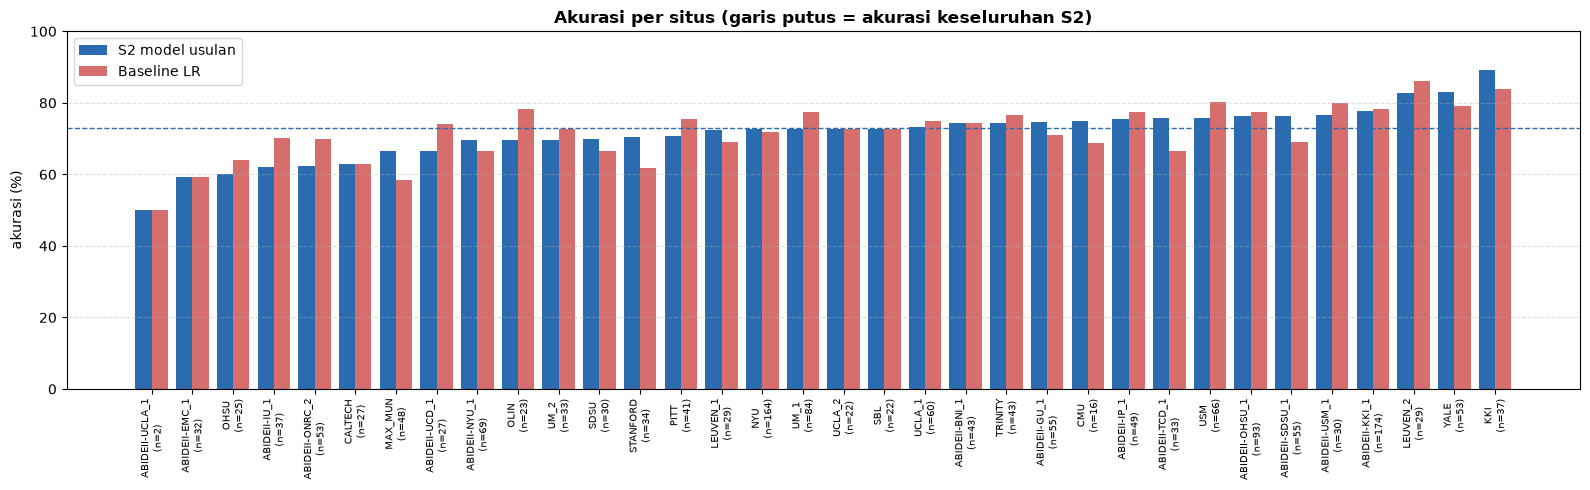

In [14]:
benar = lambda p: ((p >= 0.5).astype(int) == y)
per_ds = pd.DataFrame({"Subjek": pd.Series(dataset).value_counts(),
                       "Akurasi S2 ensemble (%)": pd.Series(benar(HASIL["p"])).groupby(dataset).mean() * 100,
                       "Akurasi LR (%)": pd.Series(benar(P_LR)).groupby(dataset).mean() * 100})
per_ds.index = per_ds.index.map({"abide1": "ABIDE I", "abide2": "ABIDE II"})
display(per_ds.round(2).style.set_caption("Akurasi per dataset"))

per_situs = (pd.DataFrame({"situs": situs, "S2": benar(HASIL["p"]), "LR": benar(P_LR)})
             .groupby("situs").agg(n=("S2", "size"), S2=("S2", "mean"), LR=("LR", "mean")).sort_values("S2"))
per_situs[["S2", "LR"]] *= 100
fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(per_situs))
ax.bar(x - 0.2, per_situs["S2"], 0.4, color="#2B6CB0", label="S2 model usulan")
ax.bar(x + 0.2, per_situs["LR"], 0.4, color="#C53030", alpha=0.7, label="Baseline LR")
ax.axhline(benar(HASIL["p"]).mean() * 100, color="#2B6CB0", ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels([f"{s}\n(n={n})" for s, n in zip(per_situs.index, per_situs["n"])], rotation=90, fontsize=7.5)
ax.set_ylabel("akurasi (%)"); ax.set_ylim(0, 100); ax.legend(); ax.grid(axis="y", alpha=0.4, ls="--")
ax.set_title("Akurasi per situs (garis putus = akurasi keseluruhan S2)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "26_4_akurasi_per_situs_s2.png", dpi=150, bbox_inches="tight")
plt.show()
per_situs.round(2).to_csv(TABEL_DIR / "26_S2_per_situs.csv")

### 8.7 Kurva belajar

Loss latih dan AUC validasi setiap epoch, untuk 5 fold × 5 run. Kurva ini dipakai untuk mengecek **overfitting**: loss latih terus turun, sementara AUC validasi berhenti naik. Titik merah adalah epoch yang bobotnya dipakai (AUC validasi terbaik).

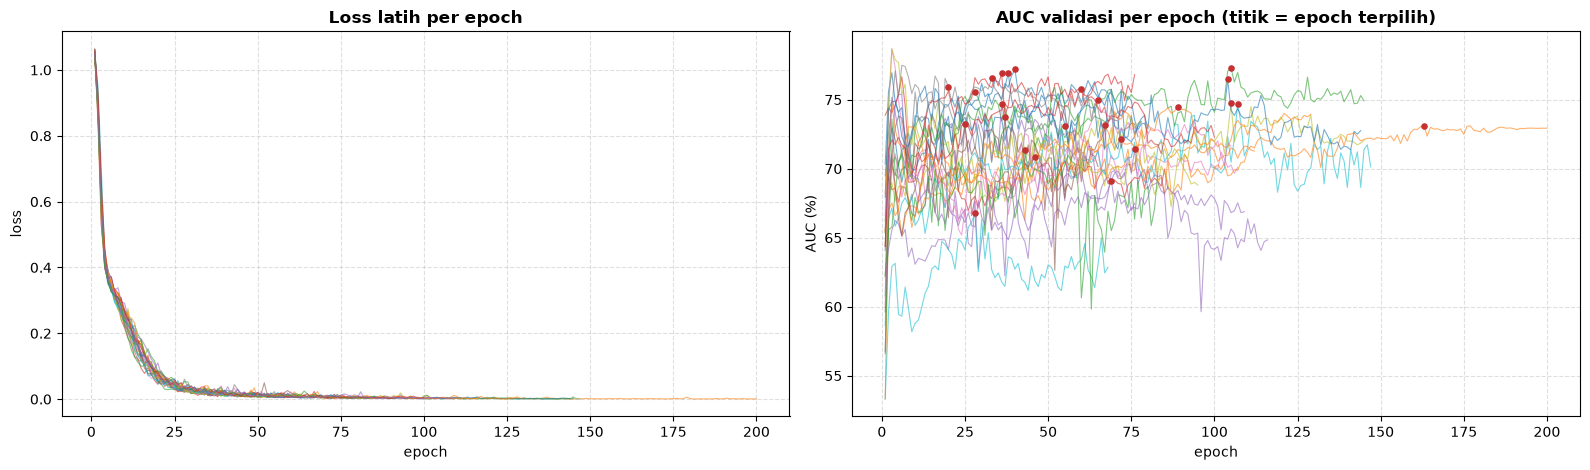

,fold,seed,epoch_terbaik,auc_val,detik
0,0,0,40,0.772000,215.293000
1,0,1,72,0.721000,314.460000
2,0,2,28,0.755000,198.291000
3,0,3,46,0.708000,252.114000
4,0,4,36,0.747000,222.857000
5,1,0,25,0.732000,187.421000
6,1,1,67,0.732000,312.656000
7,1,2,20,0.759000,176.128000
8,1,3,55,0.731000,278.090000
9,1,4,107,0.747000,431.188000


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for l in HASIL["log"]:
    r = l["riwayat"]
    axes[0].plot(r[:, 0], r[:, 1], lw=0.8, alpha=0.6)
    axes[1].plot(r[:, 0], r[:, 2] * 100, lw=0.8, alpha=0.6)
    axes[1].scatter(l["epoch_terbaik"], l["auc_val"] * 100, color="#C53030", s=14, zorder=3)
axes[0].set_title("Loss latih per epoch", fontweight="bold"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[1].set_title("AUC validasi per epoch (titik = epoch terpilih)", fontweight="bold"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("AUC (%)")
for ax in axes:
    ax.grid(alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "26_5_kurva_belajar_s2.png", dpi=150, bbox_inches="tight")
plt.show()
log_df = pd.DataFrame([{k: v for k, v in l.items() if k != "riwayat"} for l in HASIL["log"]])
display(log_df.round(3).style.set_caption("Ringkasan setiap seed"))
log_df.to_csv(TABEL_DIR / "26_S2_log_seed.csv", index=False)

### 8.8 Interpretasi: bobot cabang (β) dan parcel terpenting (α)

- **β**: seberapa besar model mengandalkan cabang graf vs cabang linear untuk setiap subjek;
- **α** (*node-attention pooling*): bobot setiap parcel dalam ringkasan graf. Nilai rata-rata 1/360 ≈ 0,0028 berarti "rata-rata". Parcel dengan α tinggi adalah wilayah yang paling diperhatikan model.

Bobot β dan α dihitung pada **subjek uji** setiap fold (rata-rata 5 run), lalu dirata-rata antar subjek.

,Parcel HCP,α rata-rata (×1000),α ASD (×1000),α Kontrol (×1000),Kali dari rata-rata
0,L_MBelt_ROI,3.140000,3.133000,3.145000,1.130000
1,R_43_ROI,3.081000,3.110000,3.059000,1.109000
2,L_3b_ROI,3.080000,3.058000,3.096000,1.109000
3,L_STV_ROI,3.072000,3.059000,3.083000,1.106000
4,R_PGi_ROI,3.071000,3.073000,3.070000,1.106000
5,L_OP4_ROI,3.070000,3.027000,3.104000,1.105000
6,L_PFm_ROI,3.070000,3.057000,3.080000,1.105000
7,R_MBelt_ROI,3.062000,3.056000,3.066000,1.102000
8,R_d32_ROI,3.060000,3.025000,3.087000,1.102000
9,R_PBelt_ROI,3.036000,2.990000,3.070000,1.093000


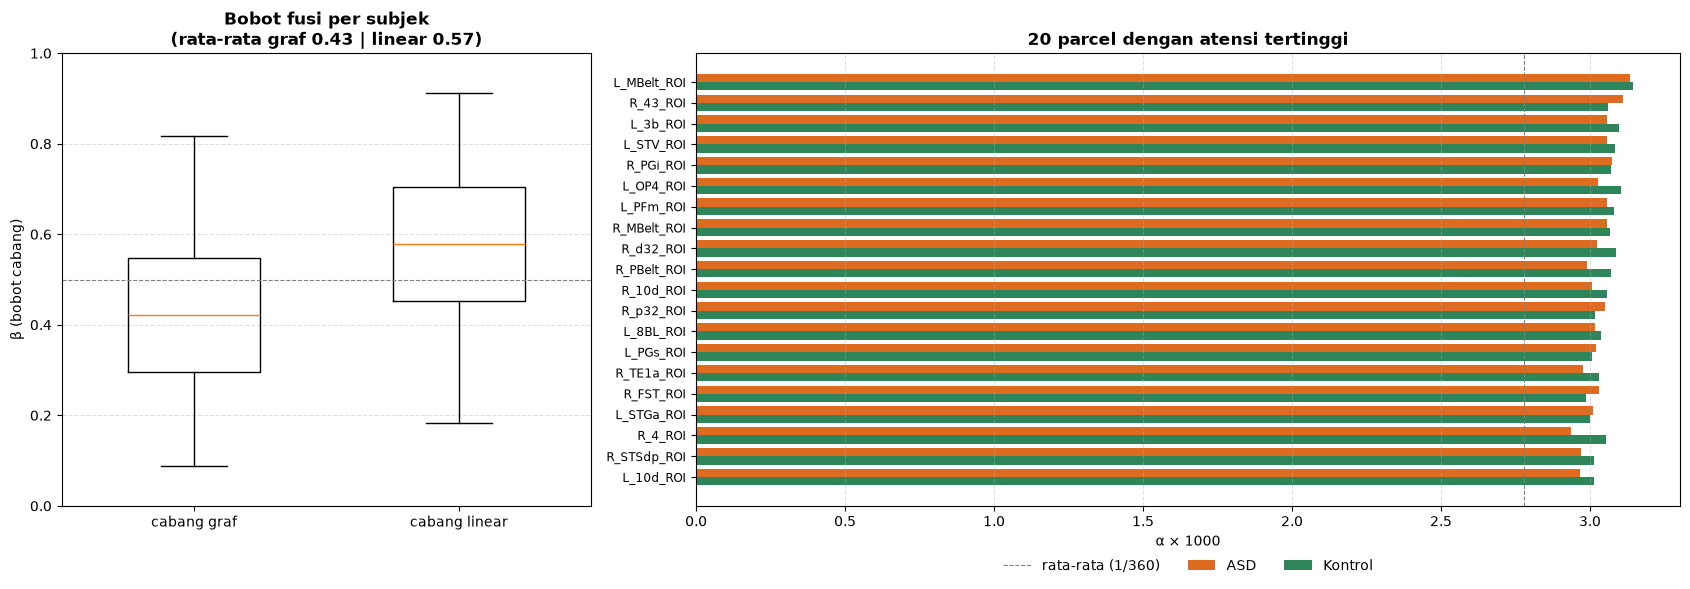

In [16]:
beta = pd.DataFrame(HASIL["beta"], columns=["graf", "linear"])
alpha = HASIL["alpha"]
rata_alpha = alpha.mean(0)
top = np.argsort(rata_alpha)[::-1][:20]
tab_roi = pd.DataFrame({"Parcel HCP": NAMA_PARCEL[top], "α rata-rata (×1000)": rata_alpha[top] * 1000,
                        "α ASD (×1000)": alpha[y == 1][:, top].mean(0) * 1000, "α Kontrol (×1000)": alpha[y == 0][:, top].mean(0) * 1000,
                        "Kali dari rata-rata": rata_alpha[top] * N_SIMPUL})
display(tab_roi.round(3).reset_index(drop=True).style.set_caption("20 parcel dengan bobot atensi tertinggi"))
tab_roi.to_csv(TABEL_DIR / "26_S2_parcel_atensi_tertinggi.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [0.7, 1.3]})
axes[0].boxplot([beta["graf"], beta["linear"]], tick_labels=["cabang graf", "cabang linear"], widths=0.5)
axes[0].axhline(0.5, color="gray", ls="--", lw=0.8)
axes[0].set_ylabel("β (bobot cabang)"); axes[0].set_ylim(0, 1)
axes[0].set_title(f"Bobot fusi per subjek\n(rata-rata graf {beta['graf'].mean():.2f} | linear {beta['linear'].mean():.2f})", fontweight="bold")
yy = np.arange(len(top))[::-1]
axes[1].barh(yy + 0.2, tab_roi["α ASD (×1000)"], 0.4, color="#DD6B20", label="ASD")
axes[1].barh(yy - 0.2, tab_roi["α Kontrol (×1000)"], 0.4, color="#2F855A", label="Kontrol")
axes[1].axvline(1000 / N_SIMPUL, color="gray", ls="--", lw=0.8, label="rata-rata (1/360)")
axes[1].set_yticks(yy); axes[1].set_yticklabels(tab_roi["Parcel HCP"], fontsize=8.5)
axes[1].set_xlabel("α × 1000"); axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False); axes[1].set_title("20 parcel dengan atensi tertinggi", fontweight="bold")
for ax in axes:
    ax.grid(axis="x" if ax is axes[1] else "y", alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "26_6_interpretasi_atensi_s2.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Cara Membaca Hasil

| Pertanyaan | Dilihat dari |
| :--- | :--- |
| Seberapa baik model usulan dengan rs-fMRI + sMRI? | baris **Rata-rata ± SD antar run** di tabel 8.1 |
| **Apakah sMRI menambah informasi dibanding S1?** | **8.4**: selisih per run, uji t berpasangan, McNemar S1 vs S2. Perhatikan juga kepala bantu cabang graf: kalau naik dari S1 (68,38%), graf memang memanfaatkan sMRI |
| Seberapa stabil hasilnya bila diulang? | SD antar run (8.1): SD kecil berarti hasil tidak bergantung keberuntungan seed |
| Apakah setara, lebih baik, atau lebih rendah dari LR? | tabel 8.3 (kolom **p Holm** dan **Kesimpulan**) |
| Apakah cabang graf menangkap sinyal sendiri? | kepala bantu cabang graf (8.2): AUC jauh di atas 50% berarti graf belajar pola bermakna |
| Apakah model seimbang antara ASD dan kontrol? | sensitivitas vs spesifisitas, balanced accuracy, confusion matrix |
| Apakah model merata di kedua dataset dan semua situs? | tabel per dataset dan grafik per situs (8.6) |
| Apakah model overfitting? | kurva belajar (8.7): epoch terpilih jauh sebelum akhir pelatihan + AUC validasi stabil |
| Cabang mana yang diandalkan, dan wilayah otak mana yang penting? | β dan α (8.8). Wilayah dengan α tinggi akan dibandingkan dengan literatur ASD di Bab 4 |

Notebook 18 (S3) memakai model dan fold yang sama, dengan tambahan cabang fenotipik (usia, jenis kelamin, FIQ).

### Kesimpulan

*(Diisi setelah melihat hasil.)*